---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 9 · Urban–rural — Hungary, the sunshine country

For Day 9 the map travels to **Hungary** — built, as a small tribute, almost entirely on
**Hungary's own open weather data**.

I was lucky enough to visit a few Junes ago, in blazing heat and brilliant sunshine — right up
until the instability kicked in and the sky put on a wicked lightning display. That is the
Hungarian summer in one afternoon: *sun by day, storms by evening.* And it is no coincidence —
the very surface heating that makes Hungary one of the sunnier corners of central Europe is what
feeds its towering summer convection.

So this day is two maps of the same country, from two national datasets, with the *urban–rural*
read written across both — the vibrant city network (Budapest and the regional centres) set on the
rural canvas of climate that shaped where people farm, holiday by **Balaton**, and now build
Europe's fastest-growing fleet of solar farms:

- **Sunshine** — mean annual sunshine duration, from **CARPATCLIM** (OMSZ / EC–JRC). The sunlit
  Great Plain glows brightest in the south-east, around **Szeged** — the *napfény városa*, the city
  of sunshine.
- **Rainfall** — mean annual precipitation, from **HungaroMet (OMSZ)**'s national gridded database.
  It is almost the mirror image: the sunny, dry plain in the east, the cloudier, wetter hills and
  west — the other half of that June memory.

This also sits where ECMWF and Hungary meet in practice: HungaroMet is an ECMWF partner, and the
day-to-day work — **EFAS**, **GRIB2**, the **European Weather Cloud (EWC)** — runs on exactly this
kind of shared, open data.

## Method

Two homogenised, gridded climatologies at 0.1°, both from Hungary's meteorological service:

1. **Sunshine duration** — CARPATCLIM daily sunshine grids (1961–2010), summed to a mean annual
   total per grid point, plus a 12-month mean for the seasonal animation.
2. **Precipitation** — OMSZ's HuClim national daily grid (1971–2025), averaged to the **1991–2020**
   WMO normal.

Both are drawn on a Lambert Conformal projection, clipped to the national border, with a light
nan-aware smoothing for a clean climatological surface. CARPATCLIM's grid begins at 17°E, so
Hungary's far-western foothills (the Alpokalja) sit just outside it — shown as faint *land, no
data*; the OMSZ rainfall grid covers the **whole** country, west included.

## Data & licence

- **Sunshine — CARPATCLIM.** *CARPATCLIM Database © European Commission – JRC, 2013*, distributed
  by **HungaroMet (OMSZ)** via [odp.met.hu](https://odp.met.hu). Free to download and use with
  acknowledgement.
- **Precipitation — HungaroMet (OMSZ) HuClim.** Homogenised gridded database, published free for
  unrestricted use on [odp.met.hu](https://odp.met.hu). Citation: *Database: Meteorological
  Database, HungaroMet Nonprofit Zrt.* (Modification of the published series requires HungaroMet's
  written consent — so this notebook downloads the raw grids and computes the climatologies locally;
  only the resulting **maps** are shared.)
- Borders, rivers and lakes: **Natural Earth** (public domain).

## Tools

| Tool | Role |
|---|---|
| `urllib` + `zipfile` | fetch the OMSZ / CARPATCLIM open grids from odp.met.hu |
| `numpy` · `xarray` | parse the gridded series, build the climatologies |
| `scipy.ndimage` | light nan-aware smoothing |
| `cartopy` · `matplotlib` | projection, clipping, render |
| `shapely` | clip the fields to the national border |
| `Pillow` | assemble the seasonal GIF |

In [1]:
import os, io, zipfile, urllib.request, warnings
import numpy as np, xarray as xr
warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True); RAW = "data/_raw"; os.makedirs(RAW, exist_ok=True)

ODP = "https://odp.met.hu/climate/homogenized_data/gridded_data_series"
CC, HU = f"{ODP}/CarpatClim_data", f"{ODP}/daily_data_series"

# small derived climatologies, cached under data/ (not redistributed — recomputed from the open raw)
SUN_NC, SUNM_NC, PR_NC = "data/day09_sunshine_clim.nc", "data/day09_sunshine_monthly.nc", "data/day09_precip_clim.nc"

def fetch(url, path):
    if not os.path.exists(path):
        print("downloading", os.path.basename(path), "..."); urllib.request.urlretrieve(url, path)
    return path

In [2]:
# --- Sunshine: CARPATCLIM daily grids -> mean annual + monthly climatology (guarded/cached) ---
if not (os.path.exists(SUN_NC) and os.path.exists(SUNM_NC)):
    z = fetch(f"{CC}/SunshineDailyGrid.zip", f"{RAW}/SunshineDailyGrid.zip")   # ~175 MB, one-off
    cf = fetch(f"{CC}/PredtandfilaGrid.dat", f"{RAW}/PredtandfilaGrid.dat")
    lon, lat = [], []
    for ln in open(cf).read().splitlines()[1:]:
        p = ln.split(); lon.append(float(p[1])); lat.append(float(p[2]))
    lon, lat = np.array(lon), np.array(lat); NG = len(lon)
    sumv = np.zeros(NG); msum = np.zeros((12, NG)); years = set()
    with zipfile.ZipFile(z) as zz, zz.open(zz.namelist()[0]) as raw:
        txt = io.TextIOWrapper(raw, encoding="ascii"); txt.readline()
        for line in txt:
            p = line.split()
            if len(p) < 4: continue
            years.add(p[0]); v = np.asarray(p[3:], dtype=np.float32)
            sumv += v; msum[int(p[1]) - 1] += v
    ny = len(years)
    LON = np.round(np.arange(17.0, 27.0001, 0.1), 1); LAT = np.round(np.arange(44.0, 50.0001, 0.1), 1)
    li = np.round((lat - 44.0)/0.1).astype(int); lj = np.round((lon - 17.0)/0.1).astype(int)
    g = np.full((LAT.size, LON.size), np.nan, np.float32); g[li, lj] = sumv/ny
    xr.Dataset({"sunshine": (("lat","lon"), g)}, coords={"lat": LAT, "lon": LON},
               attrs={"title": "CARPATCLIM mean annual sunshine 1961-2010",
                      "source": "CARPATCLIM Database (c) European Commission - JRC, 2013; HungaroMet/OMSZ",
                      "units": "h/yr"}).to_netcdf(SUN_NC)
    mg = np.full((12, LAT.size, LON.size), np.nan, np.float32)
    for m in range(12): mg[m, li, lj] = msum[m]/ny
    xr.Dataset({"sunshine": (("month","lat","lon"), mg)},
               coords={"month": np.arange(1,13), "lat": LAT, "lon": LON},
               attrs={"title": "CARPATCLIM mean monthly sunshine 1961-2010", "units": "h/month"}).to_netcdf(SUNM_NC)
    print("built sunshine climatology")
sun = xr.open_dataset(SUN_NC); sunm = xr.open_dataset(SUNM_NC)
print("sunshine grid", dict(sun.sizes), "  monthly", dict(sunm.sizes))

sunshine grid {'lat': 61, 'lon': 101}   monthly {'month': 12, 'lat': 61, 'lon': 101}


In [3]:
# --- Precipitation: OMSZ HuClim national grid -> 1991-2020 annual normal (guarded/cached) ---
if not os.path.exists(PR_NC):
    z = fetch(f"{HU}/from_1971/precipitation_sum/r_grid_19712025.txt.zip", f"{RAW}/r_grid.zip")  # ~22 MB
    cf = fetch(f"{HU}/gridpoints_coordinates.txt", f"{RAW}/hu_gridpts.txt")
    lon, lat = [], []
    for ln in open(cf).read().splitlines()[1:]:
        p = ln.split(); lon.append(float(p[1])); lat.append(float(p[2]))
    lon, lat = np.array(lon), np.array(lat); NG = len(lon); W = 8; Y0, Y1 = 1991, 2020
    sumv = np.zeros(NG); years = set()
    with zipfile.ZipFile(z) as zz, zz.open(zz.namelist()[0]) as raw:
        txt = io.TextIOWrapper(raw, encoding="ascii")
        hdr = txt.readline().rstrip("\n"); PREF = (len(hdr) - len(hdr.lstrip())) - (W - 1)
        for line in txt:                                   # fixed-width: values are the last NG*8 chars
            if len(line) < PREF + NG*W: continue
            y = int(line[0:4])
            if y < Y0 or y > Y1: continue
            v = np.frombuffer(line[PREF:PREF + NG*W].encode("ascii"), dtype="S8").astype(np.float32)
            sumv += v; years.add(y)
    ny = len(years)
    LON = np.round(np.arange(16.1, 22.9001, 0.1), 1); LAT = np.round(np.arange(45.7, 48.6001, 0.1), 1)
    li = np.round((lat - 45.7)/0.1).astype(int); lj = np.round((lon - 16.1)/0.1).astype(int)
    g = np.full((LAT.size, LON.size), np.nan, np.float32); g[li, lj] = sumv/ny
    xr.Dataset({"precip": (("lat","lon"), g)}, coords={"lat": LAT, "lon": LON},
               attrs={"title": "HuClim mean annual precipitation 1991-2020",
                      "source": "HungaroMet (OMSZ) homogenized gridded database, odp.met.hu", "units": "mm/yr"}).to_netcdf(PR_NC)
    print("built precipitation normal")
pr = xr.open_dataset(PR_NC)
print("precip grid", dict(pr.sizes))

precip grid {'lat': 30, 'lon': 69}


In [4]:
# --- shared cartography: fonts, palettes, border clip, smoothing ---
import matplotlib.pyplot as plt, matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter
import cartopy.crs as ccrs, cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.prepared import prep
from shapely.geometry import Point

plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
DB = ["Avenir Next Demi Bold", "Arial", "DejaVu Sans"]
PROJ = ccrs.LambertConformal(central_longitude=19.5, central_latitude=47.2, standard_parallels=(46, 48.5))
PC = ccrs.PlateCarree()
CMAP_SUN = LinearSegmentedColormap.from_list("sunshine",
    [(0,"#fff2cf"),(0.22,"#ffd572"),(0.44,"#f8b02f"),(0.64,"#ec861b"),(0.84,"#cf5e0c"),(1,"#9a3d03")])
CMAP_RAIN = LinearSegmentedColormap.from_list("rain",
    [(0,"#f4f9fb"),(0.22,"#d2e8f1"),(0.44,"#9ccbe0"),(0.64,"#5aa0c8"),(0.84,"#2f6fac"),(1,"#17407a")])

_shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
HUN = [r.geometry for r in shpreader.Reader(_shp).records() if r.attributes.get("NAME") == "Hungary"][0]
_HP = prep(HUN)

def smooth_mask(da, LON, LAT, sigma=0.8):
    """light nan-aware smoothing, then clip to the national border."""
    a = da.values.astype(float); m = np.isfinite(a).astype(float)
    a = np.where(m > 0, gaussian_filter(np.nan_to_num(a)*m, sigma)/np.maximum(gaussian_filter(m, sigma), 1e-6), np.nan)
    out = np.full(a.shape, np.nan, np.float32)
    for i in range(LAT.size):
        for j in range(LON.size):
            if np.isfinite(a[i, j]) and _HP.contains(Point(LON[j], LAT[i])): out[i, j] = a[i, j]
    return out

CITIES = [("Budapest",19.040,47.498,"ur"),("Debrecen",21.627,47.532,"r"),("Szeged",20.141,46.253,"r"),
          ("Pécs",18.232,46.073,"l"),("Győr",17.650,47.688,"l"),("Miskolc",20.778,48.104,"r"),
          ("Nyíregyháza",21.717,47.956,"r"),("Szombathely",16.622,47.231,"l")]
print("ready")

ready


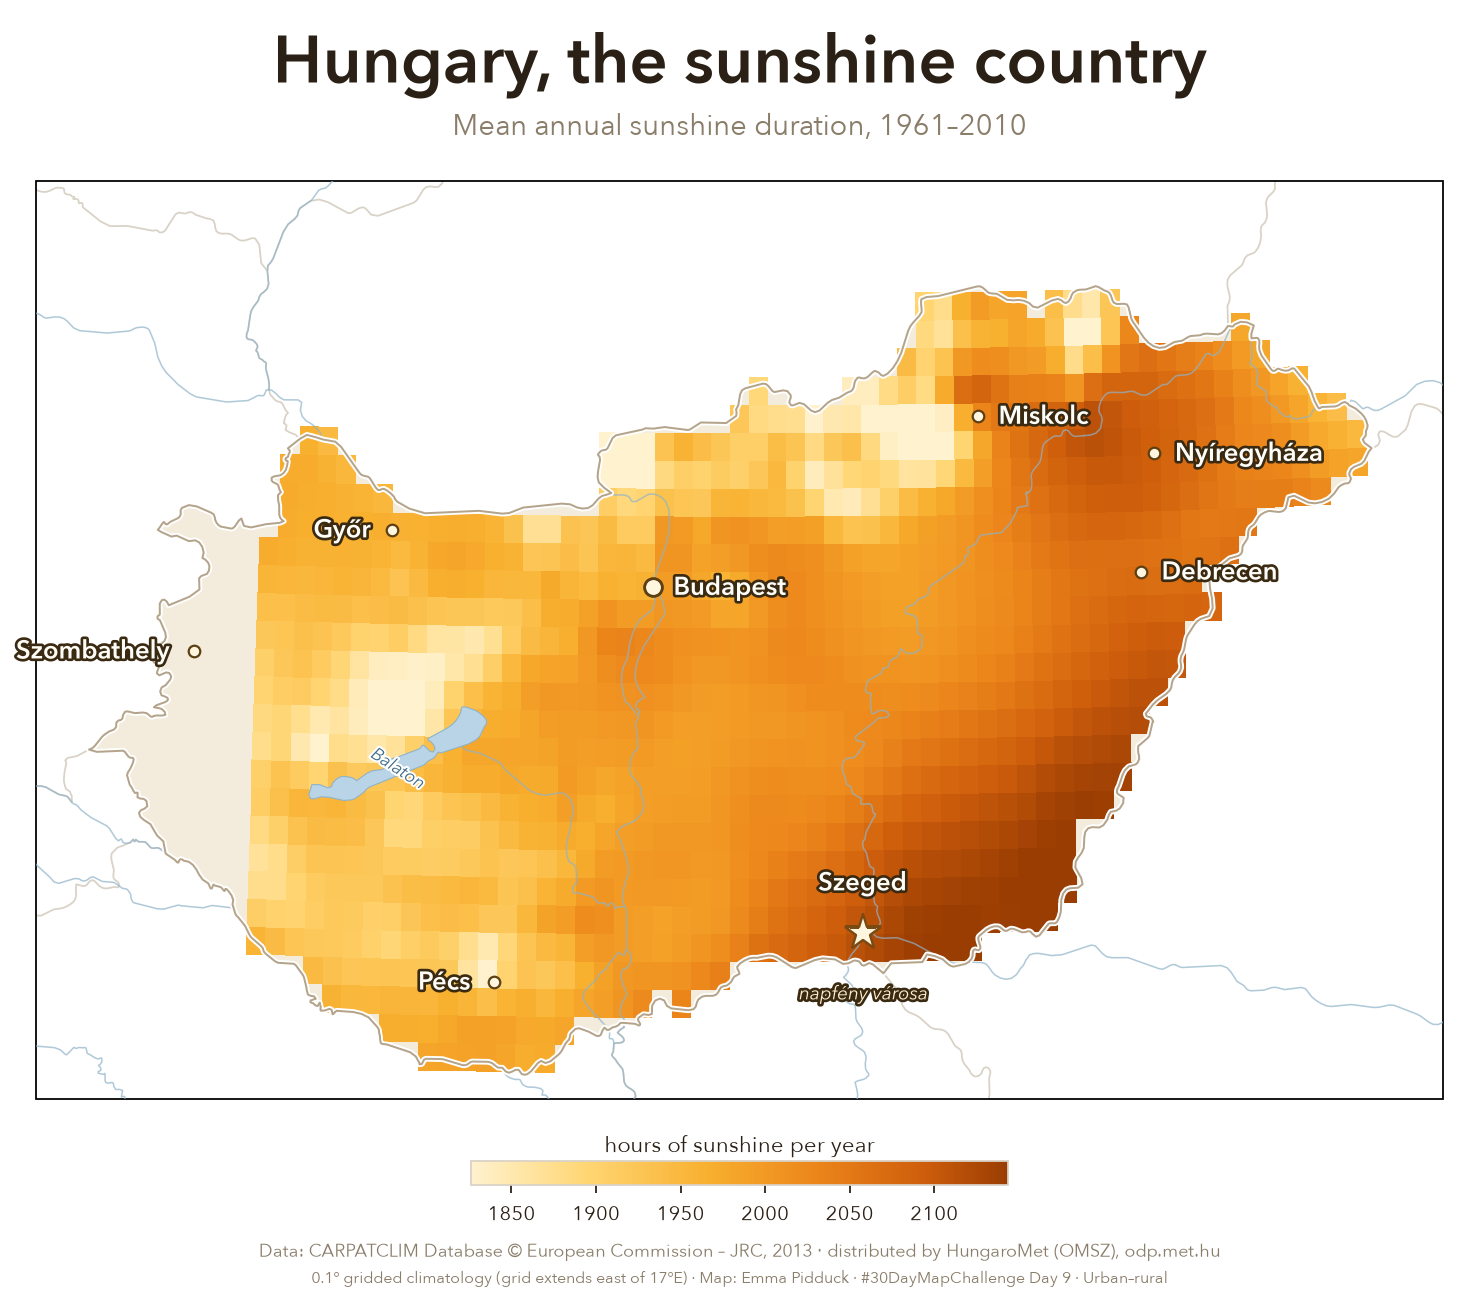

In [5]:
# --- HERO: Hungary, the sunshine country (CARPATCLIM) ---
LON, LAT = sun.lon.values, sun.lat.values
S = smooth_mask(sun["sunshine"], LON, LAT); v = S[np.isfinite(S)]
VMIN, VMAX = np.percentile(v, 2), np.percentile(v, 99)
INK, MUT = "#2a2015", "#8a7d6a"
fig = plt.figure(figsize=(10.5, 8.2), dpi=160); fig.patch.set_facecolor("white")
ax = fig.add_axes([0.02, 0.17, 0.96, 0.70], projection=PROJ); ax.set_extent([15.9, 23.1, 45.6, 48.9], crs=PC)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#d9d2c6", linewidth=0.8, zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#d9d2c6", linewidth=0.6, zorder=2)
ax.add_geometries([HUN], crs=PC, facecolor="#f3ecdd", edgecolor="none", zorder=2.5)  # west: land, no data
mesh = ax.pcolormesh(LON, LAT, S, cmap=CMAP_SUN, vmin=VMIN, vmax=VMAX, shading="auto", transform=PC, zorder=3)
ax.add_geometries([HUN], crs=PC, facecolor="none", edgecolor="#ffffff", linewidth=2.6, zorder=5)
ax.add_geometries([HUN], crs=PC, facecolor="none", edgecolor="#6b4a18", linewidth=0.9, alpha=0.5, zorder=6)
ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#8fb3c9", linewidth=0.7, alpha=0.7, zorder=4)
ax.add_feature(cfeature.LAKES.with_scale("10m"), facecolor="#b9d4e6", edgecolor="#8fb3c9", linewidth=0.5, zorder=4.6)
ax.text(17.72, 46.83, "Balaton", transform=PC, ha="center", va="center", fontsize=8, style="italic",
        color="#3d6a86", rotation=-33, zorder=9, path_effects=[pe.withStroke(linewidth=1.8, foreground="#fff")])
halo=[pe.withStroke(linewidth=2.4, foreground="#3a2a12")]
for nm,lo,la,k in CITIES:
    if k=="r" and nm=="Szeged":
        ax.plot(lo,la,marker="*",ms=17,mfc="#fff6df",mec="#7a4a12",mew=1.1,transform=PC,zorder=8)
        ax.text(lo,la+0.12,nm,transform=PC,ha="center",va="bottom",fontsize=11.5,color="#fffdf7",fontfamily=DB,zorder=9,path_effects=halo)
        ax.text(lo,la-0.17,"napfény városa",transform=PC,ha="center",va="top",fontsize=8.5,style="italic",color="#fff0cf",zorder=9,path_effects=halo)
        continue
    ax.plot(lo,la,marker="o",ms=8 if k=="ur" else 5.2,mfc="#fff6df",mec="#5c3f12",mew=1.3 if k=="ur" else 1.0,transform=PC,zorder=8)
    dx=-0.11 if k=="l" else 0.11; ha="right" if k=="l" else "left"
    ax.text(lo+dx,la,nm,transform=PC,ha=ha,va="center",fontsize=11.5,color="#fffdf7",fontfamily=DB,zorder=9,path_effects=halo)
fig.text(0.5,0.945,"Hungary, the sunshine country",ha="center",color=INK,fontsize=30,fontfamily=DB)
fig.text(0.5,0.905,"Mean annual sunshine duration, 1961–2010",ha="center",color=MUT,fontsize=13)
cax=fig.add_axes([0.34,0.105,0.32,0.018]); cb=fig.colorbar(mesh,cax=cax,orientation="horizontal")
cb.set_label("hours of sunshine per year",color=INK,fontsize=10,labelpad=4); cb.ax.xaxis.set_label_position("top")
cb.ax.tick_params(labelsize=9,colors=INK); cb.outline.set_edgecolor("#d9d2c6")
fig.text(0.5,0.050,"Data: CARPATCLIM Database © European Commission – JRC, 2013 · distributed by HungaroMet (OMSZ), odp.met.hu",ha="center",color=MUT,fontsize=8)
fig.text(0.5,0.030,"0.1° gridded climatology (grid extends east of 17°E) · Map: Emma Pidduck · #30DayMapChallenge Day 9 · Urban–rural",ha="center",color=MUT,fontsize=7.4)
fig.savefig("day09_sunshine.png", facecolor="white"); plt.show()

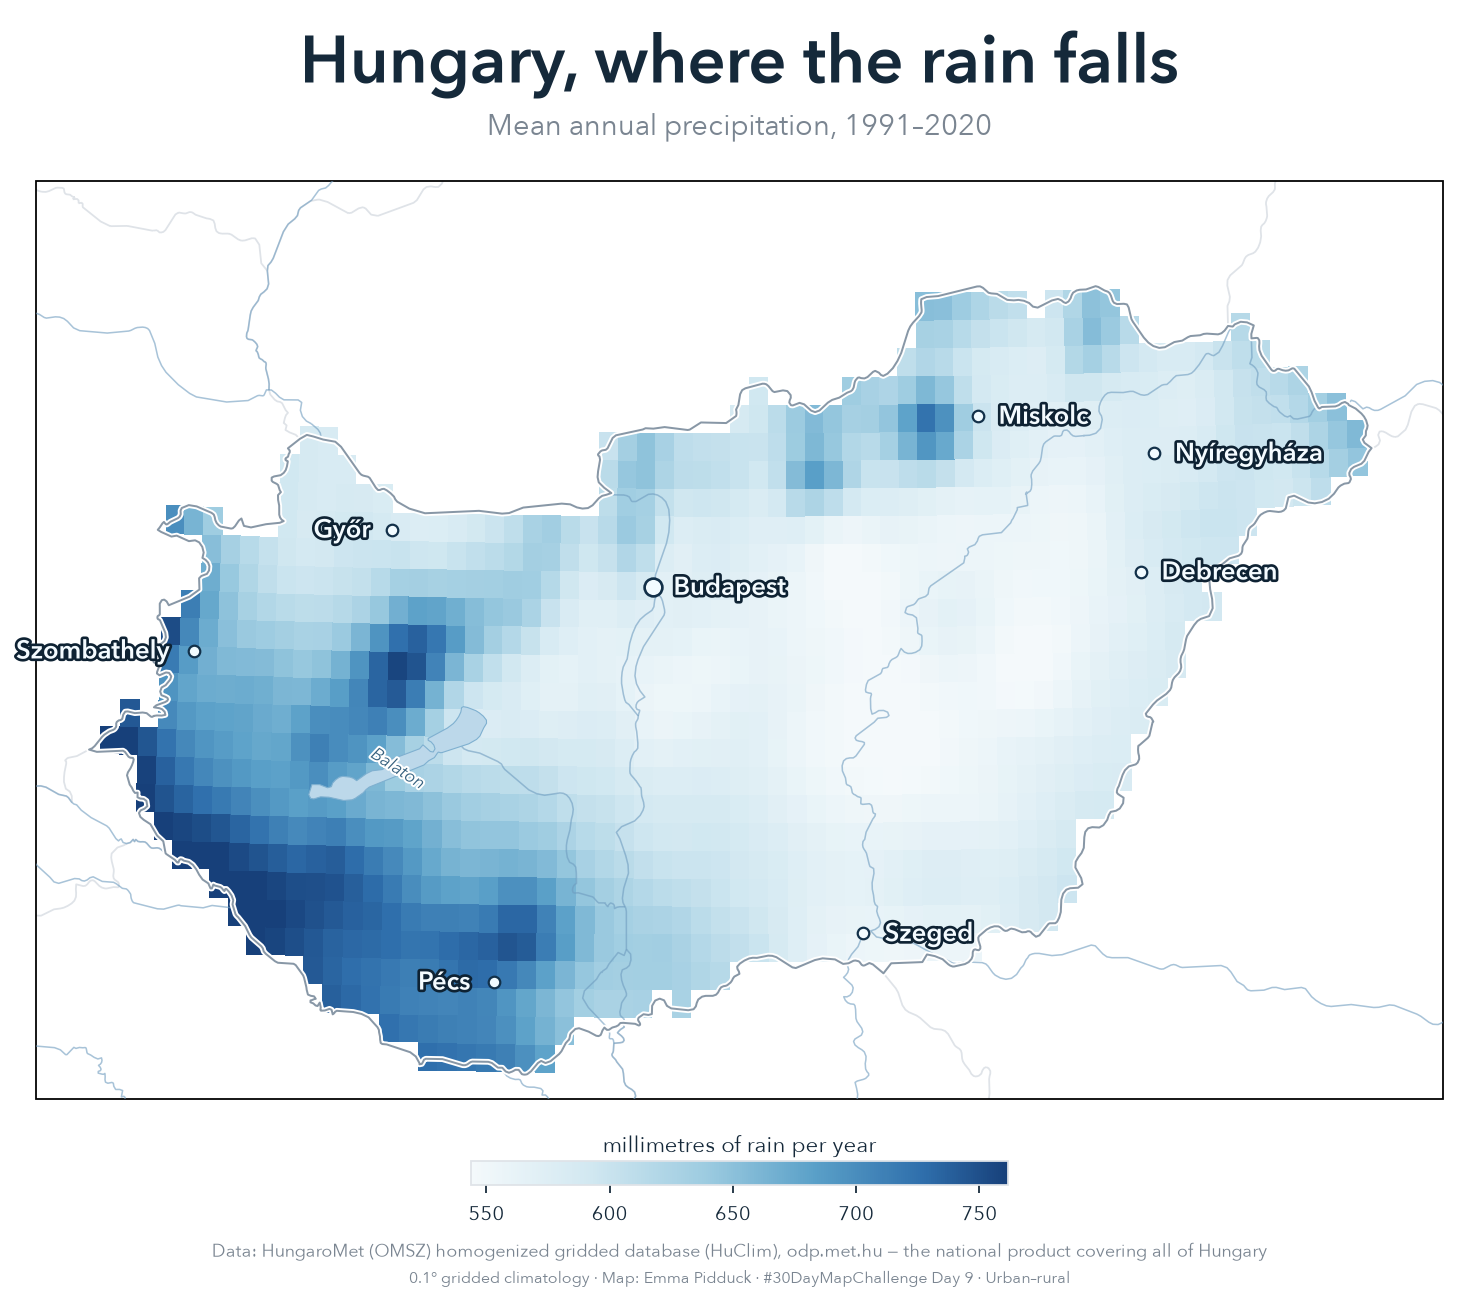

In [6]:
# --- COMPANION: Hungary, where the rain falls (OMSZ HuClim, full national coverage) ---
LON, LAT = pr.lon.values, pr.lat.values
R = smooth_mask(pr["precip"], LON, LAT); v = R[np.isfinite(R)]
VMIN, VMAX = np.percentile(v, 2), np.percentile(v, 99)
INK, MUT = "#15293a", "#7a8591"
fig = plt.figure(figsize=(10.5, 8.2), dpi=160); fig.patch.set_facecolor("white")
ax = fig.add_axes([0.02, 0.17, 0.96, 0.70], projection=PROJ); ax.set_extent([15.9, 23.1, 45.6, 48.9], crs=PC)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#dfe3e8", linewidth=0.8, zorder=2)
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#dfe3e8", linewidth=0.6, zorder=2)
mesh = ax.pcolormesh(LON, LAT, R, cmap=CMAP_RAIN, vmin=VMIN, vmax=VMAX, shading="auto", transform=PC, zorder=3)
ax.add_geometries([HUN], crs=PC, facecolor="none", edgecolor="#ffffff", linewidth=2.6, zorder=5)
ax.add_geometries([HUN], crs=PC, facecolor="none", edgecolor="#12314f", linewidth=0.9, alpha=0.5, zorder=6)
ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#6f9cbf", linewidth=0.7, alpha=0.6, zorder=4)
ax.add_feature(cfeature.LAKES.with_scale("10m"), facecolor="#bcd8ea", edgecolor="#7fb0d0", linewidth=0.5, zorder=4.6)
ax.text(17.72, 46.83, "Balaton", transform=PC, ha="center", va="center", fontsize=8, style="italic",
        color="#35607e", rotation=-33, zorder=9, path_effects=[pe.withStroke(linewidth=1.8, foreground="#fff")])
halo=[pe.withStroke(linewidth=2.4, foreground="#0e2233")]
for nm,lo,la,k in CITIES:
    ax.plot(lo,la,marker="o",ms=8 if k=="ur" else 5.2,mfc="#f2fbff",mec="#123049",mew=1.2 if k=="ur" else 1.0,transform=PC,zorder=8)
    dx=-0.11 if k=="l" else 0.11; ha="right" if k=="l" else "left"
    ax.text(lo+dx,la,nm,transform=PC,ha=ha,va="center",fontsize=11.5,color="#f4fbff",fontfamily=DB,zorder=9,path_effects=halo)
fig.text(0.5,0.945,"Hungary, where the rain falls",ha="center",color=INK,fontsize=30,fontfamily=DB)
fig.text(0.5,0.905,"Mean annual precipitation, 1991–2020",ha="center",color=MUT,fontsize=13)
cax=fig.add_axes([0.34,0.105,0.32,0.018]); cb=fig.colorbar(mesh,cax=cax,orientation="horizontal")
cb.set_label("millimetres of rain per year",color=INK,fontsize=10,labelpad=4); cb.ax.xaxis.set_label_position("top")
cb.ax.tick_params(labelsize=9,colors=INK); cb.outline.set_edgecolor("#dfe3e8")
fig.text(0.5,0.050,"Data: HungaroMet (OMSZ) homogenized gridded database (HuClim), odp.met.hu — the national product covering all of Hungary",ha="center",color=MUT,fontsize=8)
fig.text(0.5,0.030,"0.1° gridded climatology · Map: Emma Pidduck · #30DayMapChallenge Day 9 · Urban–rural",ha="center",color=MUT,fontsize=7.4)
fig.savefig("day09_rainfall.png", facecolor="white"); plt.show()

saved day09_sunshine_year.gif 0.35 MB


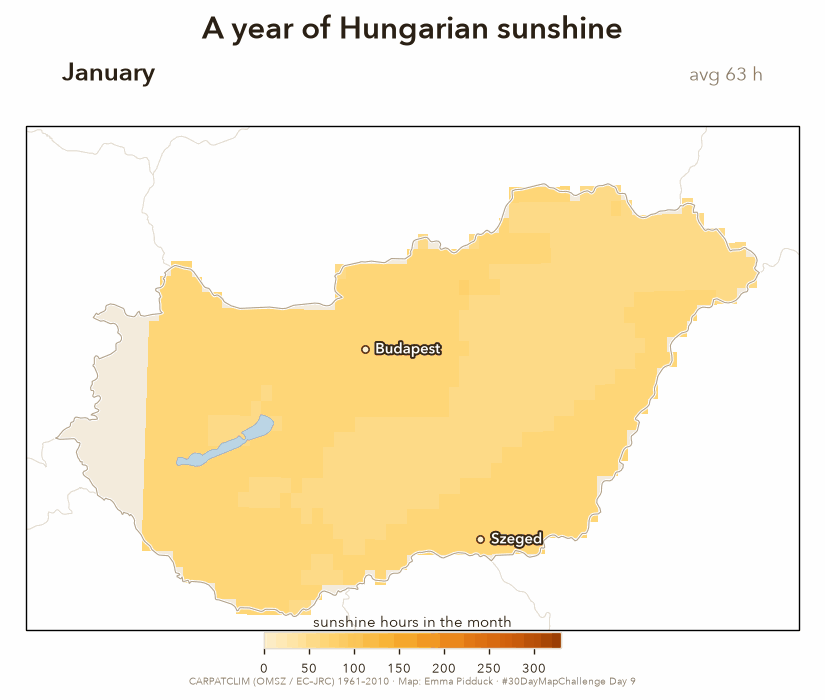

In [7]:
# --- BONUS: a year of Hungarian sunshine (seasonal GIF) ---
from PIL import Image
LON, LAT = sunm.lon.values, sunm.lat.values
MON = sunm["sunshine"].values
MN = ["January","February","March","April","May","June","July","August","September","October","November","December"]
INK, MUT = "#2a2015", "#8a7d6a"; halo=[pe.withStroke(linewidth=2.2, foreground="#3a2a12")]
frames=[]
for m in range(12):
    g = smooth_mask(sunm["sunshine"].isel(month=m), LON, LAT)
    fig = plt.figure(figsize=(6.6, 5.6), dpi=125); fig.patch.set_facecolor("white")
    ax = fig.add_axes([0.02,0.10,0.96,0.72], projection=PROJ); ax.set_extent([15.9,23.1,45.6,48.9], crs=PC)
    ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#e4ddd0", linewidth=0.6, zorder=2)
    ax.add_geometries([HUN], crs=PC, facecolor="#f3ecdd", edgecolor="none", zorder=2.5)
    mesh = ax.pcolormesh(LON, LAT, g, cmap=CMAP_SUN, vmin=0, vmax=330, shading="auto", transform=PC, zorder=3)
    ax.add_geometries([HUN], crs=PC, facecolor="none", edgecolor="#fff", linewidth=1.8, zorder=5)
    ax.add_geometries([HUN], crs=PC, facecolor="none", edgecolor="#6b4a18", linewidth=0.6, alpha=0.5, zorder=6)
    ax.add_feature(cfeature.LAKES.with_scale("10m"), facecolor="#bcd6e6", edgecolor="#8fb3c9", linewidth=0.4, zorder=4.6)
    for nm,lo,la in [("Budapest",19.040,47.498),("Szeged",20.141,46.253)]:
        ax.plot(lo,la,marker="o",ms=4.2,mfc="#fff6df",mec="#5c3f12",mew=0.9,transform=PC,zorder=8)
        ax.text(lo+0.1,la,nm,transform=PC,ha="left",va="center",fontsize=8.5,color="#fffdf7",fontfamily=DB,zorder=9,path_effects=halo)
    fig.text(0.5,0.945,"A year of Hungarian sunshine",ha="center",color=INK,fontsize=18,fontfamily=DB)
    fig.text(0.075,0.885,MN[m],ha="left",color=INK,fontsize=15,fontfamily=DB)
    fig.text(0.925,0.885,f"avg {np.nanmean(g):.0f} h",ha="right",color=MUT,fontsize=11)
    cax=fig.add_axes([0.32,0.075,0.36,0.022]); cb=fig.colorbar(mesh,cax=cax,orientation="horizontal")
    cb.set_label("sunshine hours in the month",color=INK,fontsize=8.5,labelpad=3); cb.ax.xaxis.set_label_position("top")
    cb.ax.tick_params(labelsize=7.5,colors=INK); cb.outline.set_edgecolor("#e4ddd0")
    fig.text(0.5,0.022,"CARPATCLIM (OMSZ / EC–JRC) 1961–2010 · Map: Emma Pidduck · #30DayMapChallenge Day 9",ha="center",color=MUT,fontsize=5.8)
    buf=io.BytesIO(); fig.savefig(buf, format="png", facecolor="white"); plt.close(fig)
    buf.seek(0); frames.append(Image.open(buf).convert("RGB"))
pal = frames[6].quantize(colors=96, method=Image.FASTOCTREE)
qf = [f.quantize(palette=pal, dither=Image.NONE) for f in frames]
qf[0].save("day09_sunshine_year.gif", save_all=True, append_images=qf[1:], duration=[600]*12, loop=0, optimize=True, disposal=2)
print("saved day09_sunshine_year.gif", f"{os.path.getsize('day09_sunshine_year.gif')/1e6:.2f} MB")
from IPython.display import Image as IPyImage
IPyImage(filename="day09_sunshine_year.gif")

## A note on the maps

**Sun and storms, one engine.** The south-eastern Great Plain is both the sunniest and the driest
part of Hungary; the hills and the west are cloudier and wetter. But a sunny summer is not a calm
one — the intense surface heating that piles up sunshine hours is exactly what destabilises the
afternoon atmosphere into thunderstorms. The two maps are the long-run average; the lived
experience is a brilliant morning and a spectacular evening sky.

**On the data.** These are *climatologies* — multi-decade averages, not a forecast for any
particular day. Sunshine is the CARPATCLIM 1961–2010 record; rainfall is the OMSZ 1991–2020 normal.
CARPATCLIM's grid starts at 17°E, so Hungary's western foothills fall just outside it (shown as
faint land); the OMSZ national grid covers the whole country. Both fields are lightly smoothed for a
clean climatological surface.

**Why it matters here.** HungaroMet (OMSZ) publishes all of this openly, and that openness is the
same foundation ECMWF and its partners build on — **EFAS**, **GRIB2**, the **European Weather
Cloud** — turning shared data into forecasts and services. A small map, built on a national
service's generosity, is a fitting way to say thank you.

*With thanks to HungaroMet (OMSZ) for their open data.*